# FEES: una cartera por hipótesis

Ejecutar todas las celdas en orden. Se comparan una referencia y cuatro carteras: más letras, puts de cobre, menor duración Treasury y menos MBS. La referencia cubre el bloque USD de **69%**; no replica el FEES completo. H2 usa primas teóricas, no precios observados de opciones. H1, H2 y H4 se incluyen como hipótesis fuera de la política actual, con su filtro normativo visible.

En Colab, esta celda descarga el proyecto público si no encuentra los archivos. También puede subir `entrega_fees.zip` al runtime antes de ejecutar. Los datos, las reglas y los prompts de IA forman parte de la entrega.


In [1]:
from pathlib import Path
import io
import os
import zipfile
import requests

proyecto = Path.cwd()
if not (proyecto / "config.json").exists() and (proyecto.parent / "config.json").exists():
    proyecto = proyecto.parent
if not (proyecto / "config.json").exists():
    archivo = proyecto / "entrega_fees.zip"
    if archivo.exists():
        contenido = archivo.read_bytes()
    else:
        url = "https://github.com/eldiegoveliz/presentacionasset/archive/refs/heads/analisis-fees.zip"
        respuesta = requests.get(url, timeout=60)
        respuesta.raise_for_status()
        contenido = respuesta.content
    destino = proyecto / "proyecto_fees"
    with zipfile.ZipFile(io.BytesIO(contenido)) as z:
        z.extractall(destino)
    proyecto = next(destino.rglob("config.json")).parent
os.chdir(proyecto)
print("Archivos de trabajo:", proyecto)


Archivos de trabajo: /tmp/fees-notebook-hctpwhhe/proyecto


In [2]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## Preparación

El código siguiente proviene de `analisis.py`. `config.json` fija pesos y costos antes de comparar resultados. El análisis solo lee archivos locales. `verificar.py` comprueba integridad, cálculos y moneda.


In [3]:
"""Análisis exploratorio del bloque USD del FEES. Sin optimización de pesos."""
import json
from math import erf, exp, log, sqrt
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd()


### leer_config

Leer los supuestos guardados. No ajustarlos para favorecer un resultado.

In [4]:
def leer_config():
    return json.loads((RAIZ / "config.json").read_text())

### cargar_mensuales

Comprobar precios y distribuciones. Convertir cierres diarios a retornos mensuales sin interpolar.

In [5]:
def cargar_mensuales(config):
    """Fin de mes disponible; exigir meses completos y fechas comunes en los ETF."""
    series, calidad = {}, []
    indices = []
    for ticker in config["etfs"]:
        d = pd.read_csv(RAIZ / f"data/raw/{ticker}.csv", index_col=0, parse_dates=True)
        if d.index.has_duplicates or not d.index.is_monotonic_increasing or d.isna().any().any():
            raise ValueError(f"Fechas o valores inválidos: {ticker}")
        if (d[["cierre", "ajustado"]] <= 0).any().any():
            raise ValueError(f"Precios no positivos: {ticker}")
        d = d.loc[config["inicio_descarga"]:config["corte"]]
        indices.append(d.index)
        # Contrastar ajuste de Yahoo con precio + dividendo en la fecha ex-dividendo.
        reconstruido = (d.cierre + d.dividendo) / d.cierre.shift(1) - 1
        ajustado = d.ajustado.pct_change(fill_method=None)
        error = float((reconstruido - ajustado).abs().max())
        if error > 0.001:
            raise ValueError(f"Ajuste de dividendos de {ticker} difiere más de 10 pb: {error}")
        mensual = d.ajustado.resample("ME").last()
        fechas = pd.Series(d.index, index=d.index).resample("ME").last()
        if mensual.isna().any() or ((mensual.index - pd.DatetimeIndex(fechas)).days > 7).any():
            raise ValueError(f"Mes faltante o cierre alejado de fin de mes: {ticker}")
        series[ticker] = mensual
        calidad.append({"ticker": ticker, "filas": len(d), "primera": str(d.index.min().date()),
                        "ultima": str(d.index.max().date()), "dividendos": int((d.dividendo != 0).sum()),
                        "max_error_retorno_pb": error * 10000})
    if any(not i.equals(indices[0]) for i in indices[1:]):
        raise ValueError("Los ETF tienen fechas distintas. Revisar, no rellenar silenciosamente.")
    precios = pd.DataFrame(series)
    precios = precios.loc[:config["corte"]]
    if precios.isna().any().any():
        raise ValueError("Precios mensuales incompletos")
    retornos = precios.pct_change(fill_method=None).iloc[1:]
    esperados = pd.date_range(retornos.index.min(), pd.Timestamp(config["corte"]), freq="ME")
    if not retornos.index.equals(esperados):
        raise ValueError("Faltan meses hasta el corte configurado. No extender el período por suposición.")
    return retornos, pd.DataFrame(calidad).set_index("ticker")

### pesos_escenario

Definir una cartera por hipótesis. Los pesos sobre el fondo suman 69%; los cambios de asignación se identifican por separado.

In [6]:
def pesos_escenario(config, escenario):
    """Una cartera por hipótesis. Los cambios de política se rotulan por separado."""
    w = pd.Series(config["pesos_fondo_usd"], dtype=float)
    traspaso = escenario["traspaso"]
    if traspaso < 0:
        raise ValueError("El traspaso debe ser positivo")
    if traspaso:
        if escenario["origen"] not in w or escenario["destino"] not in w:
            raise ValueError("Instrumento ajeno al bloque de renta fija")
        w[escenario["origen"]] -= traspaso
        w[escenario["destino"]] += traspaso
    if (w < 0).any() or not np.isclose(w.sum(), 0.69):
        raise ValueError("Pesos negativos o bloque distinto de 69%")
    if escenario["tipo"] in ("referencia", "puts", "duracion"):
        if not np.allclose(w[["BIL", "STIP", "MBB"]], [0.10, 0.04, 0.15]):
            raise ValueError("Este escenario no puede cambiar pesos estratégicos de clases")
        if not np.isclose(w[["SHY", "IEI", "IEF"]].sum(), 0.40):
            raise ValueError("La asignación Treasury de este escenario debe mantenerse en 40%")
    elif escenario["tipo"] not in ("liquidez", "mbs"):
        raise ValueError("Tipo de cartera no reconocido")
    return w

### cartera

Sumar pesos por retornos, rebalancear cada mes y descontar costos sobre compras más ventas.

In [7]:
def cartera(retornos, pesos, costo=0.0005):
    """Rebalanceo mensual; costo por cada dólar comprado o vendido, sin dividir por dos."""
    w = pesos / pesos.sum()
    r = retornos.loc[:, w.index]
    bruto = r.dot(w)
    # Pesos que quedan después de la rentabilidad del mes previo.
    despues = r.add(1).mul(w).div(1 + bruto, axis=0)
    transado = despues.shift(1).sub(w).abs().sum(axis=1)
    transado.iloc[0] = 1.0  # Compra inicial desde efectivo.
    neto = (1 - costo * transado) * (1 + bruto) - 1
    return neto

### riqueza_y_caida

Acumular retornos e incluir el capital inicial al medir pérdidas desde máximos.

In [8]:
def riqueza_y_caida(retornos):
    riqueza = (1 + retornos).cumprod()
    # El capital inicial es 1: incluirlo evita esconder una caída en el primer mes.
    maximo = riqueza.cummax().clip(lower=1)
    return riqueza, riqueza / maximo - 1

### metricas

Calcular retorno compuesto anual, volatilidad anual, mayor caída mensual y peor mes.

In [9]:
def metricas(retornos):
    _, caida = riqueza_y_caida(retornos)
    return pd.DataFrame({"retorno_anual_pct": ((1 + retornos).prod() ** (12 / len(retornos)) - 1) * 100,
                         "volatilidad_anual_pct": retornos.std(ddof=1) * np.sqrt(12) * 100,
                         "caida_max_mensual_pct": caida.min() * 100,
                         "peor_mes_pct": retornos.min() * 100})

### bootstrap_media

Remuestrear las diferencias en bloques de meses. No confundir el intervalo de medias con uno de CAGR.

In [10]:
def bootstrap_media(diferencia, bloque, repeticiones, semilla):
    """Mismos meses para ambas carteras; bloques circulares preservan dependencia local."""
    valores = np.asarray(diferencia)
    n = len(valores)
    rng = np.random.default_rng(semilla)
    inicios = rng.integers(0, n, size=(repeticiones, int(np.ceil(n / bloque))))
    indices = (inicios[:, :, None] + np.arange(bloque)) % n
    muestras = valores[indices.reshape(repeticiones, -1)[:, :n]]
    return np.quantile(muestras.mean(axis=1) * 12 * 100, [0.025, 0.975])

### precio_put_black76

Calcular la prima teórica europea. El modelo no sustituye precios de opciones reales.

In [11]:
def precio_put_black76(futuro, strike, volatilidad, tasa, plazo):
    """Prima teórica europea por unidad. No es una cotización de una opción real."""
    if futuro <= 0 or strike <= 0 or volatilidad < 0 or plazo < 0:
        raise ValueError("Parámetros inválidos para la put")
    if plazo == 0:
        return max(strike - futuro, 0)
    if volatilidad == 0:
        return exp(-tasa * plazo) * max(strike - futuro, 0)
    d1 = (log(futuro / strike) + 0.5 * volatilidad ** 2 * plazo) / (volatilidad * sqrt(plazo))
    d2 = d1 - volatilidad * sqrt(plazo)
    normal_menos_d1 = 0.5 * (1 + erf(-d1 / sqrt(2)))
    normal_menos_d2 = 0.5 * (1 + erf(-d2 / sqrt(2)))
    return exp(-tasa * plazo) * (strike * normal_menos_d2 - futuro * normal_menos_d1)

### preparar_insumos_puts

Desplazar un mes precios iniciales, tasa y volatilidad. Cada compra usa solo datos anteriores al pago.

In [12]:
def preparar_insumos_puts(cobre, tasa, ventana):
    """Alinear el mes del pago con precios, volatilidad y tasa conocidos al entrar."""
    mensual = cobre.resample("ME").last()
    sigma = np.log(cobre / cobre.shift(1)).rolling(ventana).std(ddof=1) * np.sqrt(252)
    return pd.DataFrame({"futuro_inicial": mensual.shift(1), "futuro_final": mensual,
                         "sigma_hist_entrada": sigma.resample("ME").last().shift(1),
                         "tasa_entrada": tasa.resample("ME").last().shift(1) / 100})

### cargar_insumos_puts

Leer cobre continuo HG=F y tasa DGS1MO. Comprobar cierres recientes y dejar visible el calentamiento de volatilidad.

In [13]:
def cargar_insumos_puts(config):
    cobre = pd.read_csv(RAIZ / f"data/raw/{config['cobre']}.csv", index_col=0, parse_dates=True).cierre
    tasa = pd.read_csv(RAIZ / "data/raw/DGS1MO.csv", index_col=0, parse_dates=True).DGS1MO
    for serie in (cobre, tasa):
        fechas = pd.Series(serie.dropna().index, index=serie.dropna().index).resample("ME").last()
        if fechas.isna().any() or ((fechas.index - pd.DatetimeIndex(fechas)).days > 7).any():
            raise ValueError("Cobre o tasa sin cierre mensual reciente")
    return preparar_insumos_puts(cobre.dropna(), tasa, config["puts"]["ventana_vol_dias"])

### cartera_puts

Comprar una put mensual pagada con BIL. Restar prima, fricción e ingreso sacrificado, sumar el pago y rebalancear tenencias reales.

In [14]:
def cartera_puts(retornos, pesos, insumos, parametros, costo):
    """Cartera base + put mensual, pagada vendiendo letras. Sin exposición futura desnuda."""
    d = insumos.reindex(retornos.index).copy()
    if d.isna().any().any() or (d[["futuro_inicial", "futuro_final", "sigma_hist_entrada"]] <= 0).any().any():
        raise ValueError("Faltan insumos anteriores a la compra de puts o hay valores inválidos")
    h = parametros["nocional_sobre_fondo"]
    k = parametros["strike_sobre_futuro"]
    friccion = parametros["friccion_sobre_prima"]
    if not 0 <= h <= 1 or k <= 0 or friccion < 0 or parametros["multiplicador_vol"] <= 0:
        raise ValueError("Parámetros económicos inválidos para la cobertura")
    d["strike"] = k * d.futuro_inicial
    d["vol_modelo"] = parametros["multiplicador_vol"] * d.sigma_hist_entrada
    d["prima_por_libra_modelo"] = [precio_put_black76(f, strike, sigma, tasa, parametros["plazo_anios"])
                                    for f, strike, sigma, tasa in zip(d.futuro_inicial, d.strike, d.vol_modelo, d.tasa_entrada)]
    d["prima_sobre_fondo"] = h * d.prima_por_libra_modelo / d.futuro_inicial
    d["friccion_sobre_fondo"] = friccion * d.prima_sobre_fondo
    d["payoff_sobre_fondo"] = h * (d.strike - d.futuro_final).clip(lower=0) / d.futuro_inicial
    pagado = d.prima_sobre_fondo + d.friccion_sobre_fondo
    if (pagado > pesos["BIL"]).any():
        raise ValueError("La prima y sus costos superan las letras disponibles: no se permite endeudamiento")
    # El dinero de prima y fricción deja de ganar el retorno de BIL ese mes.
    d["ingreso_BIL_sacrificado"] = pagado * retornos.BIL
    d["aporte_neto_bloque"] = (d.payoff_sobre_fondo - pagado - d.ingreso_BIL_sacrificado) / pesos.sum()
    base = cartera(retornos, pesos, costo)
    objetivo = pesos / pesos.sum()
    anteriores = None
    rendimientos, costos = [], []
    for fecha, r_mes in retornos[objetivo.index].iterrows():
        # Al vencer, el pago entra en BIL. El mes siguiente se rebalancea
        # desde las tenencias reales, incluidos los pagos o pérdidas del seguro.
        transado = 1.0 if anteriores is None else (objetivo - anteriores).abs().sum()
        factor = 1 - costo * transado
        tenencias = objetivo * factor
        tenencias["BIL"] -= factor * pagado.loc[fecha] / pesos.sum()
        final = tenencias * (1 + r_mes)
        final["BIL"] += factor * d.loc[fecha, "payoff_sobre_fondo"] / pesos.sum()
        riqueza_final = final.sum()
        if riqueza_final <= 0:
            raise ValueError("Capital agotado en la simulación")
        rendimientos.append(riqueza_final - 1)
        costos.append(costo * transado)
        anteriores = final / riqueza_final
    d["retorno_cartera"] = rendimientos
    d["costo_rebalanceo_bloque"] = costos
    d["aporte_tras_costos_base"] = d.retorno_cartera - base
    return d.retorno_cartera, d

### comparar_carteras

Ejecutar la referencia y las cuatro hipótesis con el mismo calendario y reglas de costo.

In [15]:
def comparar_carteras(retornos, config, insumos, costo=None):
    costo = config["costo_por_dolar_transado"] if costo is None else costo
    pesos, carteras, auditoria = {}, {}, None
    for escenario in config["carteras"]:
        nombre = escenario["nombre"]
        w = pesos_escenario(config, escenario)
        pesos[nombre] = w
        if escenario["tipo"] == "puts":
            carteras[nombre], auditoria = cartera_puts(retornos, w, insumos, config["puts"], costo)
        else:
            carteras[nombre] = cartera(retornos, w, costo)
    return pd.DataFrame(carteras), pd.DataFrame(pesos), auditoria

### clasificar_carteras

Mostrar qué hipótesis requiere cambiar la política. Una simulación no equivale a autorización de inversión.

In [16]:
def clasificar_carteras(config):
    estados = {"referencia": "Referencia proxy; cumplimiento no certificado",
               "liquidez": "Requiere cambiar asignacion y evaluar riesgo ex ante",
               "puts": "Instrumento fuera de la politica consultada; simulacion teorica",
               "duracion": "Pesos de clases conservados; TE ex ante no verificado",
               "mbs": "Requiere cambiar el 15% estrategico de MBS"}
    return pd.DataFrame([{"cartera": e["nombre"], "hipotesis": e["hipotesis"],
                          "estado_normativo": estados[e["tipo"]],
                          "evidencia": "Primas teoricas, subyacente continuo proxy" if e["tipo"] == "puts" else "Retornos ETF proxy"}
                         for e in config["carteras"]]).set_index("cartera")

### ejecutar

Comparar todos los escenarios y períodos definidos. Guardar tablas, gráficos y sensibilidad sin elegir un ganador.

In [17]:
def ejecutar():
    config = leer_config()
    salida = RAIZ / "results"
    figuras = salida / "figuras"
    figuras.mkdir(parents=True, exist_ok=True)
    todos, calidad = cargar_mensuales(config)
    insumos = cargar_insumos_puts(config)
    r = todos.loc[config["inicio_analisis"]:]
    portafolios, pesos, auditoria = comparar_carteras(r, config, insumos)
    referencia = portafolios.iloc[:, 0]
    estados = clasificar_carteras(config)
    resumen = metricas(portafolios)
    resumen["diferencia_cagr_pp"] = resumen.retorno_anual_pct - resumen.retorno_anual_pct.iloc[0]
    resumen["te_proxy_soberano_pb"] = np.nan
    soberanos = [t for t in pesos.index if t != "MBB"]
    for e in config["carteras"]:
        if e["tipo"] in ("referencia", "liquidez", "duracion"):
            cambio = pesos[e["nombre"]] - pesos.iloc[:, 0]
            activo = r[soberanos].dot(cambio[soberanos]) / 0.85
            resumen.loc[e["nombre"], "te_proxy_soberano_pb"] = activo.std(ddof=1) * np.sqrt(12) * 10000
    for nombre, tabla in {"calidad_datos": calidad, "retornos_activos_mensuales": todos,
                          "pesos_sobre_fondo": pesos, "retornos_carteras_mensuales": portafolios,
                          "metricas": resumen, "estado_carteras": estados, "puts_auditoria": auditoria}.items():
        tabla.to_csv(salida / f"{nombre}.csv")

    sensibilidad = []
    for inicio, fin, periodo in [("2015", "2019", "2015-2019"), ("2020", "2021", "2020-2021"),
                                  ("2022", "2022", "2022"), ("2023", config["corte"], "2023-corte")]:
        carteras, _, _ = comparar_carteras(todos.loc[inicio:fin], config, insumos)
        m = metricas(carteras)
        m["periodo"] = periodo
        m["meses"] = len(carteras)
        sensibilidad.append(m.reset_index(names="cartera"))
    sensibilidad = pd.concat(sensibilidad, ignore_index=True)
    sensibilidad.to_csv(salida / "sensibilidad_periodos.csv", index=False)
    costos = []
    for costo in (0, config["costo_por_dolar_transado"], 0.001):
        carteras, _, _ = comparar_carteras(r, config, insumos, costo)
        m = metricas(carteras)
        m["costo_pb_por_dolar"] = costo * 10000
        costos.append(m.reset_index(names="cartera"))
    pd.concat(costos).to_csv(salida / "sensibilidad_costos.csv", index=False)

    incertidumbre = []
    for nombre in portafolios.columns[1:]:
        delta = portafolios[nombre] - referencia
        for bloque in (3, 6, 12):
            inferior, superior = bootstrap_media(delta, bloque, config["bootstrap_repeticiones"], config["semilla"])
            incertidumbre.append({"cartera": nombre, "bloque_meses": bloque,
                                  "media_anualizada_pp": delta.mean() * 12 * 100,
                                  "ic95_inferior_pp": inferior, "ic95_superior_pp": superior})
    incertidumbre = pd.DataFrame(incertidumbre)
    incertidumbre.to_csv(salida / "incertidumbre.csv", index=False)

    sensibilidad_puts = []
    for strike in (0.90, 0.95, 1.00):
        for vol in (1.0, 1.25, 1.5):
            for h in (0.05, 0.10, 0.20):
                parametros = dict(config["puts"], strike_sobre_futuro=strike,
                                  multiplicador_vol=vol, nocional_sobre_fondo=h)
                sim, _ = cartera_puts(r, pesos.iloc[:, 0], insumos, parametros, config["costo_por_dolar_transado"])
                m = metricas(sim.to_frame("H2")).iloc[0].to_dict()
                sensibilidad_puts.append(dict(m, strike=strike, multiplicador_vol=vol, nocional=h))
    sensibilidad_puts = pd.DataFrame(sensibilidad_puts)
    sensibilidad_puts.to_csv(salida / "sensibilidad_puts.csv", index=False)
    sensibilidad_mbs = []
    for peso_mbs in (0.10, 0.15, 0.20):
        w = pesos.iloc[:, 0].copy()
        w.MBB = peso_mbs
        w.BIL += 0.15 - peso_mbs
        m = metricas(cartera(r, w, config["costo_por_dolar_transado"]).to_frame("MBS")).iloc[0].to_dict()
        sensibilidad_mbs.append(dict(m, peso_mbs_sobre_fondo=peso_mbs))
    sensibilidad_mbs = pd.DataFrame(sensibilidad_mbs)
    sensibilidad_mbs.to_csv(salida / "sensibilidad_mbs.csv", index=False)

    correlaciones = []
    for inicio, fin, periodo in [("2014", "2019", "2014-2019"), ("2020", "2021", "2020-2021"),
                                  ("2022", "2022", "2022"), ("2023", config["corte"], "2023-corte")]:
        sub = todos.loc[inicio:fin]
        for bono in ("SHY", "IEI", "IEF", "MBB"):
            correlaciones.append({"periodo": periodo, "bono": bono, "meses": len(sub),
                                   "correlacion_SPY": sub[bono].corr(sub.SPY),
                                   "ambos_negativos_meses": int(((sub[bono] < 0) & (sub.SPY < 0)).sum())})
    correlaciones = pd.DataFrame(correlaciones)
    correlaciones.to_csv(salida / "correlaciones.csv", index=False)
    estres = []
    for inicio, fin, periodo in [("2020-01", "2020-03", "2020 T1"), ("2022", "2022", "2022")]:
        estres.append(((1 + portafolios.loc[inicio:fin]).prod() - 1).rename(periodo))
    estres = pd.DataFrame(estres) * 100
    estres.to_csv(salida / "estres.csv")

    fx = pd.read_csv(RAIZ / f"data/raw/{config['tipo_cambio']}.csv", index_col=0, parse_dates=True).cierre
    fx_mensual = fx.resample("ME").last().loc[todos.index.min() - pd.offsets.MonthEnd(1):config["corte"]]
    fechas_fx = pd.Series(fx.dropna().index, index=fx.dropna().index).resample("ME").last()
    if fx_mensual.isna().any() or ((fechas_fx.index - pd.DatetimeIndex(fechas_fx)).days > 7).any():
        raise ValueError("Faltan cierres de FX. No rellenar.")
    cambio = fx_mensual.pct_change(fill_method=None).reindex(r.index)
    if cambio.isna().any():
        raise ValueError("FX sin alinear con carteras")
    clp = (1 + portafolios).mul(1 + cambio, axis=0) - 1
    clp.to_csv(salida / "retornos_carteras_clp.csv")
    metricas(clp).to_csv(salida / "metricas_clp.csv")

    plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                         "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})
    riqueza, caida = riqueza_y_caida(portafolios)
    origen = portafolios.index[0] - pd.offsets.MonthEnd(1)
    riqueza = pd.concat([pd.DataFrame(1., index=[origen], columns=riqueza.columns), riqueza])
    for tabla, nombre, titulo, unidad in [(100 * riqueza, "riqueza", "Referencia y una cartera por hipotesis: bloque USD", "USD por 100 iniciales"),
                                          (100 * caida, "caidas", "Caidas mensuales: cuatro hipotesis", "Caida (%)")]:
        ax = tabla.plot(title=titulo)
        ax.set_ylabel(unidad); ax.set_xlabel("")
        plt.tight_layout(); plt.savefig(figuras / f"{nombre}.png", dpi=160); plt.close()
    movil = pd.DataFrame({b: todos[b].rolling(12).corr(todos.SPY) for b in ("SHY", "IEI", "IEF", "MBB")})
    movil.to_csv(salida / "correlacion_movil_12m.csv")
    ax = movil.plot(title="Correlacion con SPY: retornos mensuales, ventana de 12 meses", ylim=(-1, 1))
    ax.axhline(0, color="black", linewidth=0.7); ax.set_ylabel("Correlacion"); ax.set_xlabel("")
    plt.tight_layout(); plt.savefig(figuras / "correlacion.png", dpi=160); plt.close()
    tasas = pd.concat([pd.read_csv(RAIZ / f"data/raw/{s}.csv", index_col=0, parse_dates=True)[s]
                       for s in ("DGS1MO", "DGS2", "DGS10")], axis=1)
    ax = tasas.loc[config["inicio_analisis"]:].plot(title="Tasas FRED: descuento de puts y contexto, no retornos")
    ax.set_ylabel("Tasa anual (%)"); ax.set_xlabel("")
    plt.tight_layout(); plt.savefig(figuras / "tasas.png", dpi=160); plt.close()
    fig, ax = plt.subplots()
    ax.bar(auditoria.index, auditoria.payoff_sobre_fondo * 100, width=20, label="Pago put (modelo)")
    ax.bar(auditoria.index, -(auditoria.prima_sobre_fondo + auditoria.friccion_sobre_fondo) * 100,
           width=20, label="Prima y friccion (modelo)")
    ax.set_title("H2: pagos y costo mensual de puts teoricas")
    ax.set_ylabel("% del capital total hipotetico al inicio del mes")
    ax.legend(); plt.tight_layout(); plt.savefig(figuras / "puts.png", dpi=160); plt.close()

    informe(config, resumen, pesos, estados, correlaciones, incertidumbre, sensibilidad,
            sensibilidad_puts, sensibilidad_mbs, auditoria, estres, metricas(clp), len(r))
    print(resumen.round(3).to_string())
    print(f"\nReferencia + {len(portafolios.columns) - 1} carteras. {len(r)} meses. Informe: {salida / 'informe.md'}")
    return resumen

### informe

Escribir el mini informe directamente desde las tablas calculadas. Los límites de las conclusiones quedan junto a los resultados.

In [18]:
def informe(config, resumen, pesos, estados, correlaciones, incertidumbre, sensibilidad,
            sensibilidad_puts, sensibilidad_mbs, auditoria, estres, clp, n):
    tabla_pesos = (100 * pesos.T).round(3)
    tabla_pesos["nocional_put_pct"] = [100 * config["puts"]["nocional_sobre_fondo"] if e["tipo"] == "puts" else 0
                                        for e in config["carteras"]]
    corr = correlaciones.pivot(index="periodo", columns="bono", values="correlacion_SPY")
    intervalo = incertidumbre.loc[incertidumbre.bloque_meses == 6]
    h2 = resumen.loc["H2 Puts cobre (modelo)"]
    prima_media = auditoria.prima_sobre_fondo.mean() * 12 * 100
    pago_medio = auditoria.payoff_sobre_fondo.mean() * 12 * 100
    cae_cobre = auditoria.futuro_final / auditoria.futuro_inicial - 1 < -0.05
    aporte_en_caidas = auditoria.loc[cae_cobre, "aporte_tras_costos_base"].mean() * 100
    rejilla = sensibilidad_puts.loc[np.isclose(sensibilidad_puts.nocional, config["puts"]["nocional_sobre_fondo"])]
    texto = f"""# FEES: una cartera por hipótesis

Se comparan **una referencia y cuatro carteras distintas**, una por idea del usuario. Datos hasta {config['corte']}, {n} meses desde enero de 2020. Ejecutar `python analisis.py` para regenerar todas las cifras.

La referencia aproxima el bloque USD de **69%** de la asignación estratégica. Faltan Europa 19%, Japón 9% y China 3%. Las métricas son por 100 invertidos en ese bloque y no representan el retorno del FEES completo. La política actual aplicada al pasado es un contrafactual, incluso antes de noviembre de 2023.

**H2 incluye primas y pagos teóricos de puts, no precios históricos observados de opciones.** Se incorpora para estudiar la idea, con su costo y sus límites. Simularla no significa que esté autorizada por la política vigente.

## Diseño de las cuatro carteras

- **H1, más letras:** mover 10 pp del fondo desde Treasury 7–10 años (IEF) hacia letras (BIL). Es la traducción propuesta por el asistente de reducir exposición a bonos largos cuando su correlación con acciones preocupa. No incorpora acciones ni activa señales según correlaciones futuras. Cambia la asignación estratégica.
- **H2, puts de cobre:** conservar la cartera de referencia y comprar puts hipotéticas cada mes. Nocional equivalente a 10% del fondo, strike 95% del precio inicial y plazo 1/12 de año. La prima y fricción se financian reduciendo BIL ese mes. No se posee un futuro descubierto.
- **H3, menor duración:** mover 2 pp desde IEF hacia SHY (Treasury 1–3 años). Conservar el 40% total de Treasuries, el 10% de letras y el 15% MBS.
- **H4, menos MBS:** reducir MBB del 15% al 10% y subir BIL del 10% al 15%. La sensibilidad también prueba 20% MBS. Estos cambios requieren modificar la asignación.

Pesos sobre el fondo completo, **no normalizados**. Suman 69%; el 31% no modelado se supone idéntico entre escenarios. La última columna es nocional subyacente de la opción y no se suma a los pesos de activos. La prima efectiva de H2 varía cada mes y se descuenta de BIL.

{tabla_pesos.to_markdown()}

## Filtro normativo

{estados.to_markdown()}

Las restricciones se mantienen como criterio de decisión: las carteras fuera de política se muestran como hipótesis y no se recomiendan para ejecución bajo las reglas actuales. Los ETFs son proxies, no órdenes elegibles certificadas. El TE realizado aproximado no reemplaza el cálculo ex ante del custodio. H2 y H4 no reciben un TE soberano, porque ese número no decidiría su admisibilidad.

## Comparación del bloque USD

Retorno compuesto y volatilidad anual en %, caída y peor mes en %. La caída incluye el capital inicial y solo observa cierres mensuales. Diferencia CAGR en puntos porcentuales; TE proxy en puntos base anuales del mandato soberano 85%, suponiendo idéntico el resto.

{resumen.round(3).to_markdown()}

![Referencia y cuatro carteras](figuras/riqueza.png)

![Caídas mensuales](figuras/caidas.png)

## Qué produce la simulación de puts

Con los supuestos centrales, H2 devuelve {h2.retorno_anual_pct:.2f}% anual del bloque, con caída máxima mensual de {h2.caida_max_mensual_pct:.2f}%. La prima media anualizada es {prima_media:.2f}% del capital total hipotético tras el costo de rebalanceo de cada mes y los pagos medios anualizados son {pago_medio:.2f}%. Son promedios mensuales por 12, no sumas de caja sobre un capital inicial constante.

Hubo {int(cae_cobre.sum())} meses de caída del proxy del cobre superior a 5%. En ellos, la diferencia media H2 menos referencia fue {aporte_en_caidas:.2f} pp mensuales del bloque. Esto describe la protección frente a ese subyacente y el costo del seguro. **No demuestra cobertura de ingresos fiscales ni de todas las pérdidas de bonos.** No se modelan ingresos tributarios, producción ni retiros del FEES.

![Primas y pagos de puts teóricas](figuras/puts.png)

El CSV `puts_auditoria.csv` guarda para cada mes precio inicial y final, strike, volatilidad histórica conocida al entrar, volatilidad del modelo, tasa, prima, fricción, pago y retorno. Permite seguir el cálculo de un mes sin una caja negra.

La valoración usa **Black-76 europeo**, con volatilidad de los 63 retornos diarios anteriores multiplicada por {config['puts']['multiplicador_vol']}. Ese multiplicador es un supuesto, no volatilidad implícita observada. Se añade fricción del {config['puts']['friccion_sobre_prima'] * 100:.0f}% de la prima. Se descuenta el rendimiento BIL sacrificado al pagar prima y fricción. El programa rechaza una prima superior a las letras disponibles.

`HG=F` es un proxy continuo: el precio inicial y final pueden corresponder a vencimientos distintos. Por ello se simula una **opción europea hipotética sobre ese proxy**, no contratos COMEX históricos identificados. No se replica el rollover de un contrato negociable, el ejercicio americano, la entrega del futuro, la malla de strikes, el spread real ni contratos enteros de 25.000 libras. Los resultados son condicionales y no constituyen un backtest ejecutable de opciones reales.

## Sensibilidad del seguro y de MBS

La siguiente tabla mantiene el nocional de 10% y varía strike y multiplicador de volatilidad. `sensibilidad_puts.csv` contiene las 27 combinaciones de strikes 90/95/100%, volatilidad histórica por 1/1,25/1,5 y nocionales 5/10/20%. Se muestran todas sin elegir la mejor.

{rejilla.round(3).to_markdown(index=False)}

Para MBS, cada cambio se financia con letras. El 15% es la referencia oficial; 10% y 20% son alternativas hipotéticas que cambian la asignación.

{sensibilidad_mbs.round(3).to_markdown(index=False)}

## Correlación, estrés e incertidumbre

La primera hipótesis se evalúa con su propia cartera y con el diagnóstico de correlación. SPY solo se usa para diagnóstico. Una correlación positiva no implica ausencia total de diversificación.

{corr.round(3).to_markdown()}

![Correlación móvil](figuras/correlacion.png)

Retornos acumulados en episodios fijados por calendario. H2 sigue dependiendo de primas teóricas.

{estres.round(3).to_markdown()}

Bootstrap pareado circular con {config['bootstrap_repeticiones']} repeticiones y semilla {config['semilla']}. Aquí se muestran bloques de seis meses; `incertidumbre.csv` también incluye 3 y 12. Intervalos individuales del 95% para diferencias de **medias mensuales por 12**, en pp anuales, no diferencias de CAGR. No corrigen comparaciones múltiples ni la selección retrospectiva. En H2 tampoco incorporan error de valoración de opciones.

{intervalo.round(3).to_markdown(index=False)}

`sensibilidad_periodos.csv` compara 2015–2019, 2020–2021, 2022 y 2023–corte con las mismas cinco carteras. La ventana anterior a 2020 comienza en 2015 para asegurar calentamiento de volatilidad del cobre. `sensibilidad_costos.csv` prueba 0/5/10 pb de costos de activos; la fricción propia de puts se mantiene separada.

## Moneda y límites

Conversión ilustrativa a CLP: `(1 + retorno USD) × (1 + cambio CLP por USD) − 1`, con Yahoo CLP=X. No es dólar observado y sus horarios pueden diferir del cierre de ETF.

{clp.round(3).to_markdown()}

Rebalanceo mensual, sin aportes ni retiros, con costo de {config['costo_por_dolar_transado'] * 10000:.0f} pb por dólar comprado o vendido, incluida la compra inicial. Los cierres ajustados aproximan reinversión de distribuciones y ya incluyen gastos internos de ETF. FRED DGS1MO se usa solo como proxy de descuento para la prima; DGS2/DGS10 dan contexto. Ninguna variación de tasas se interpreta como retorno de bonos.

La referencia divide el 40% Treasury en tercios SHY/IEI/IEF, supuesto que no replica ponderaciones por capitalización. STIP es TIPS 0–5 años, distinto del comparador 1–10. Los demás ETF también tienen desajustes de índice, gastos y gestión. Sin índices oficiales ni cartera global no se certifica rendimiento efectivo ni cumplimiento del FEES. Las hipótesis se diseñaron con conocimiento del pasado; no hay validación independiente fuera de muestra.

## Fuentes

[Política FEES](https://www.hacienda.cl/areas-de-trabajo/finanzas-internacionales/fondos-soberanos/fondo-de-estabilizacion-economica-y-social/politica-de-inversion), [directrices vigentes](https://www.hacienda.cl/areas-de-trabajo/finanzas-internacionales/fondos-soberanos/fondo-de-estabilizacion-economica-y-social/politica-de-inversion/pauta-de-inversion-vigente), [Yahoo cobre](https://finance.yahoo.com/quote/HG=F/), [FRED DGS1MO](https://fred.stlouisfed.org/series/DGS1MO), [Black (1976)](https://doi.org/10.1016/0304-405X(76)90024-6), [CME: opciones de cobre](https://www.cmegroup.com/markets/metals/base/copper.contractSpecs.options.html), [CME: datos históricos DataMine](https://www.cmegroup.com/datamine.html). Las URLs exactas y hashes de las descargas están en `data/metadatos.json`.

El alcance académico completo también requiere FRP. Siguen pendientes la revisión y defensa del equipo, el memo final y las firmas del anexo IA.
"""
    (RAIZ / "results/informe.md").write_text(texto)
    # Resumen portable para presentar las cinco carteras en el hilo.
    filas = []
    escala = max(resumen.retorno_anual_pct.abs().max(), 1)
    for nombre, fila in resumen.iterrows():
        valor = fila.retorno_anual_pct
        ancho = abs(valor) / escala * 48
        izquierda = 50 if valor >= 0 else 50 - ancho
        filas.append(f'<div class="fila"><span>{nombre}</span><div class="pista"><i class="cero"></i>'
                     f'<i class="barra" style="left:{izquierda:.1f}%;width:{ancho:.1f}%"></i></div>'
                     f'<strong>{valor:.2f}%</strong></div>')
    html = '''<!doctype html><html lang="es"><meta charset="utf-8"><style>
body{margin:0;color:var(--foreground);font-family:var(--font-sans)}h3{font-size:17px;margin:0 0 10px}
.nota{font-size:13px;color:var(--muted-foreground);line-height:1.5}
.fila{display:grid;grid-template-columns:170px minmax(0,1fr) 56px;align-items:center;gap:8px;height:43px;font-size:13px}
.pista{position:relative;height:26px;background:var(--secondary);border-radius:var(--radius)}
.cero{position:absolute;left:50%;height:100%;width:1px;background:var(--foreground);opacity:.4}
.barra{position:absolute;top:4px;height:18px;background:var(--chart-1);border-radius:3px}
strong{text-align:right;font-family:var(--font-mono)}
</style><body><h3>Referencia y una cartera por hipótesis</h3>
<p class="nota">Retorno compuesto anual del bloque USD (69% de la asignación), enero 2020–octubre 2026.</p>'''
    html += "".join(filas) + '''<p class="nota">H2 usa primas teóricas y un proxy continuo de cobre.
H1, H2 y H4 requieren cambios de política. Ninguna cartera tiene cumplimiento certificado.
Fuente: analisis.py, results/metricas.csv.</p></body></html>'''
    (RAIZ / "results/resumen.html").write_text(html)

## Ejecutar el análisis

Todas las cifras del informe salen de esta ejecución.

In [19]:
resumen = ejecutar()
display(resumen.round(3))

                        retorno_anual_pct  volatilidad_anual_pct  caida_max_mensual_pct  peor_mes_pct  diferencia_cagr_pp  te_proxy_soberano_pb
Referencia proxy USD                1.268                  4.018                -11.088        -2.965               0.000                 0.000
H1 Mas letras                       1.695                  3.010                 -7.904        -2.249               0.426                85.210
H2 Puts cobre (modelo)             -1.009                  4.146                -16.470        -3.342              -2.277                   NaN
H3 Treasury corto                   1.326                  3.861                -10.617        -2.863               0.058                13.566
H4 Menos MBS                        1.426                  3.587                 -9.940        -2.581               0.157                   NaN

Referencia + 4 carteras. 82 meses. Informe: /tmp/fees-notebook-hctpwhhe/proyecto/results/informe.md


,retorno_anual_pct,volatilidad_anual_pct,caida_max_mensual_pct,peor_mes_pct,diferencia_cagr_pp,te_proxy_soberano_pb
Referencia proxy USD,1.268,4.018,-11.088,-2.965,0.000,0.000
H1 Mas letras,1.695,3.010,-7.904,-2.249,0.426,85.210
H2 Puts cobre (modelo),-1.009,4.146,-16.470,-3.342,-2.277,NaN
H3 Treasury corto,1.326,3.861,-10.617,-2.863,0.058,13.566
H4 Menos MBS,1.426,3.587,-9.940,-2.581,0.157,NaN


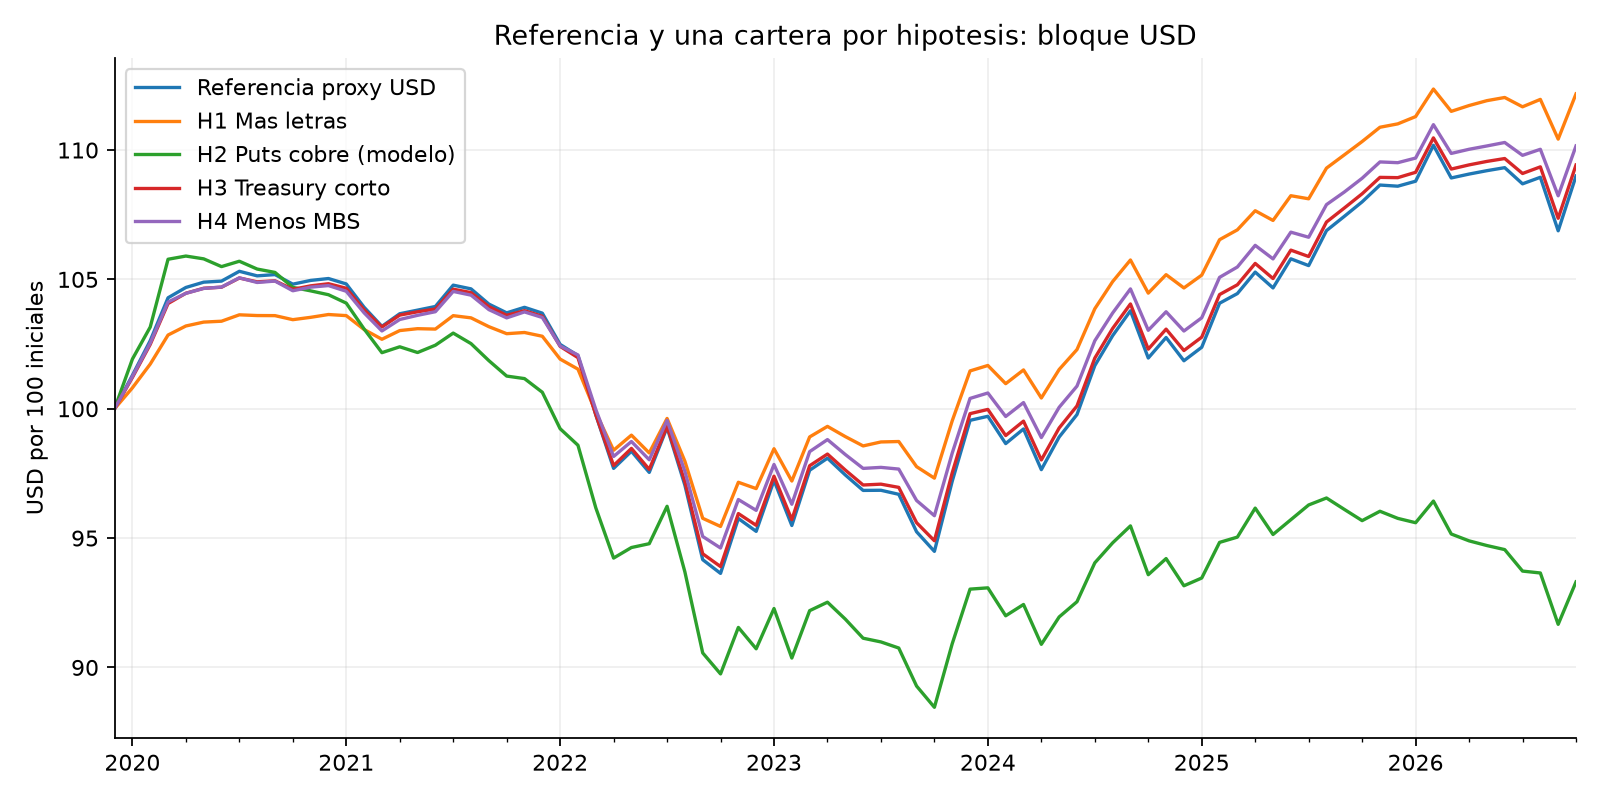

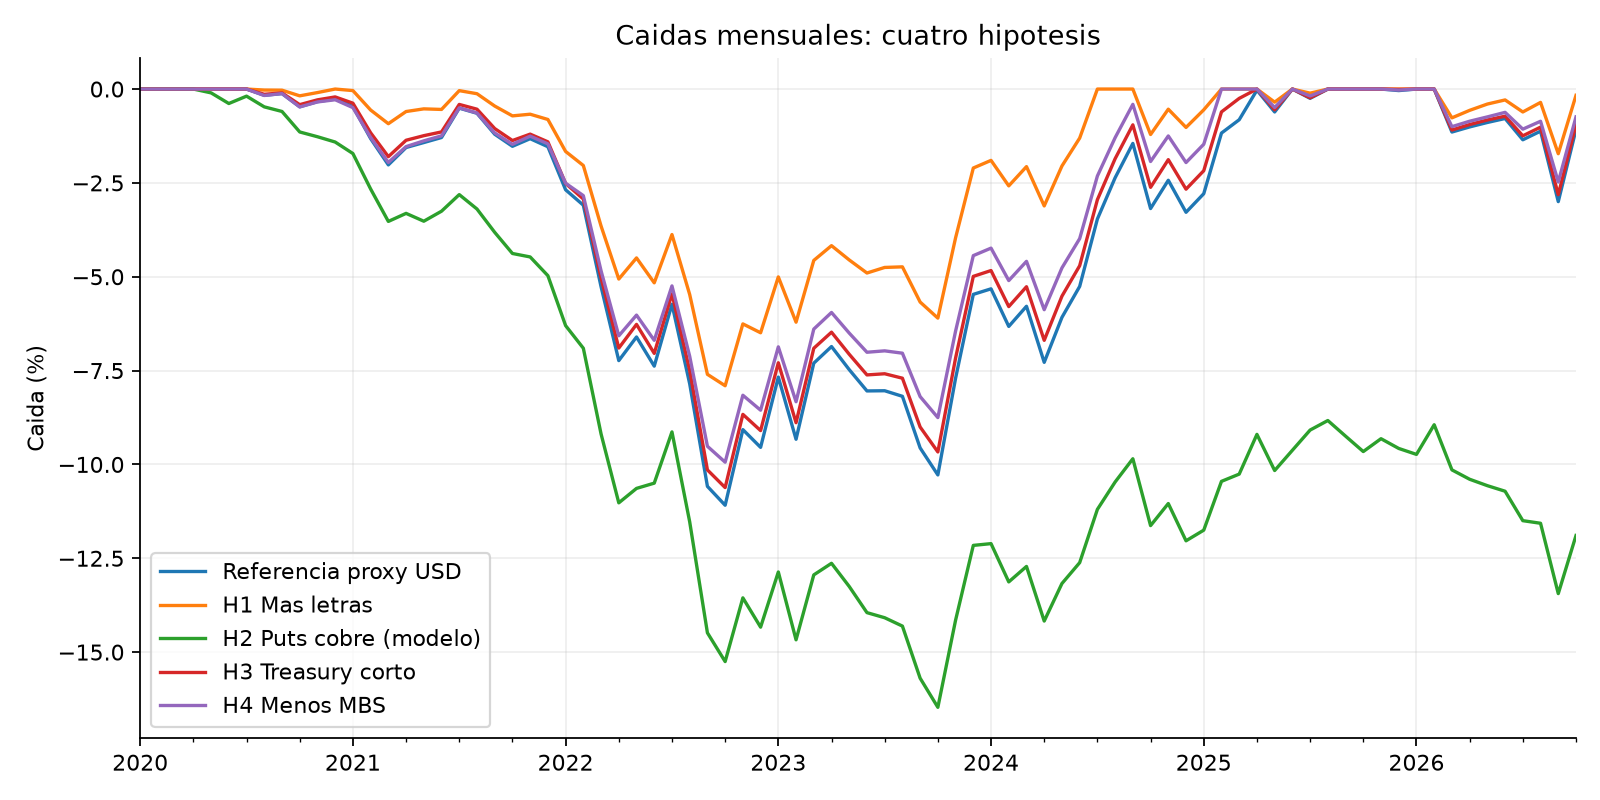

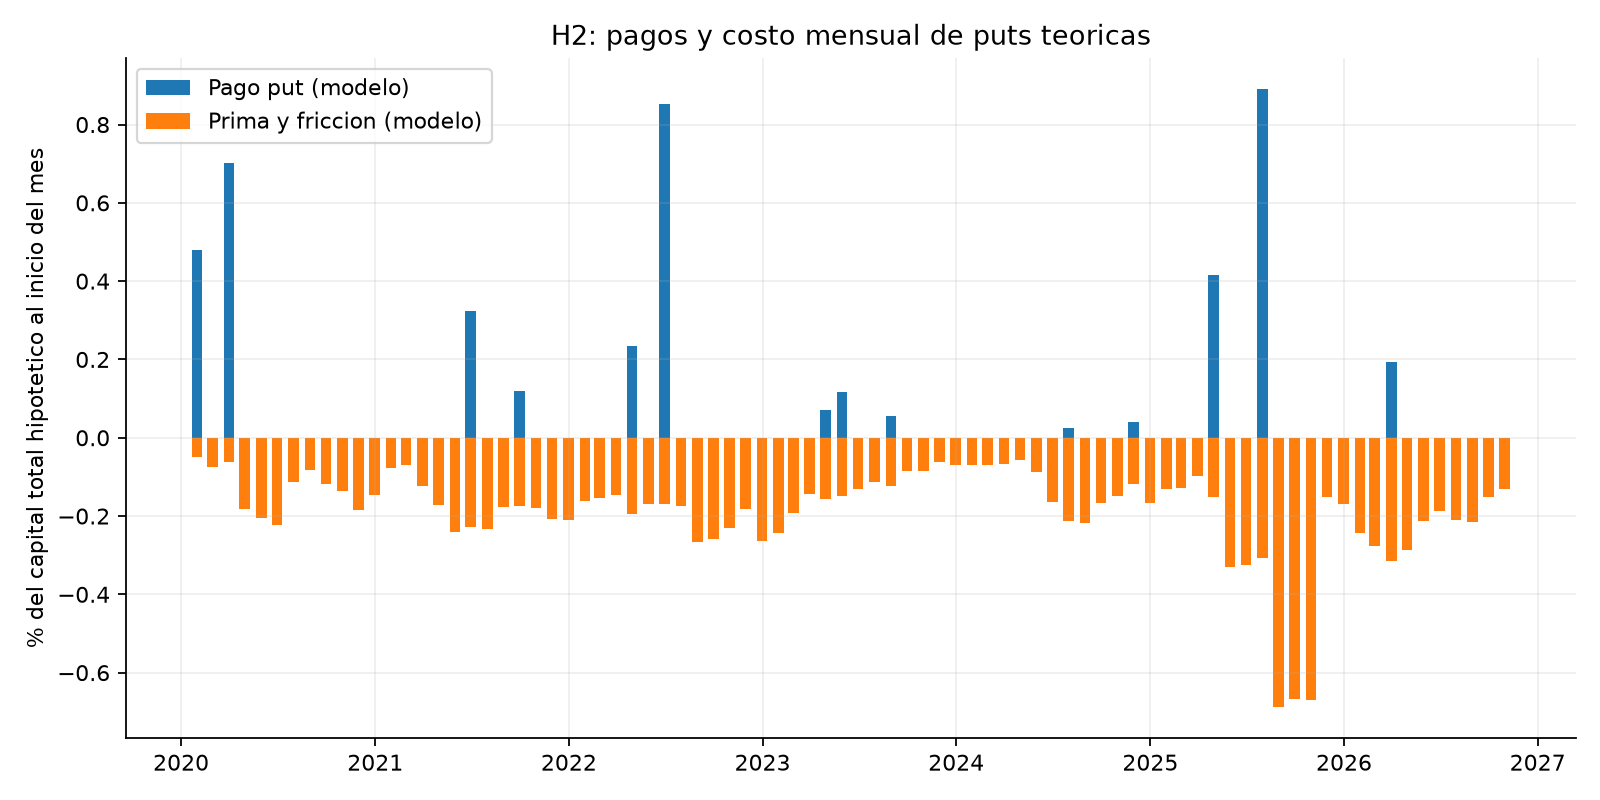

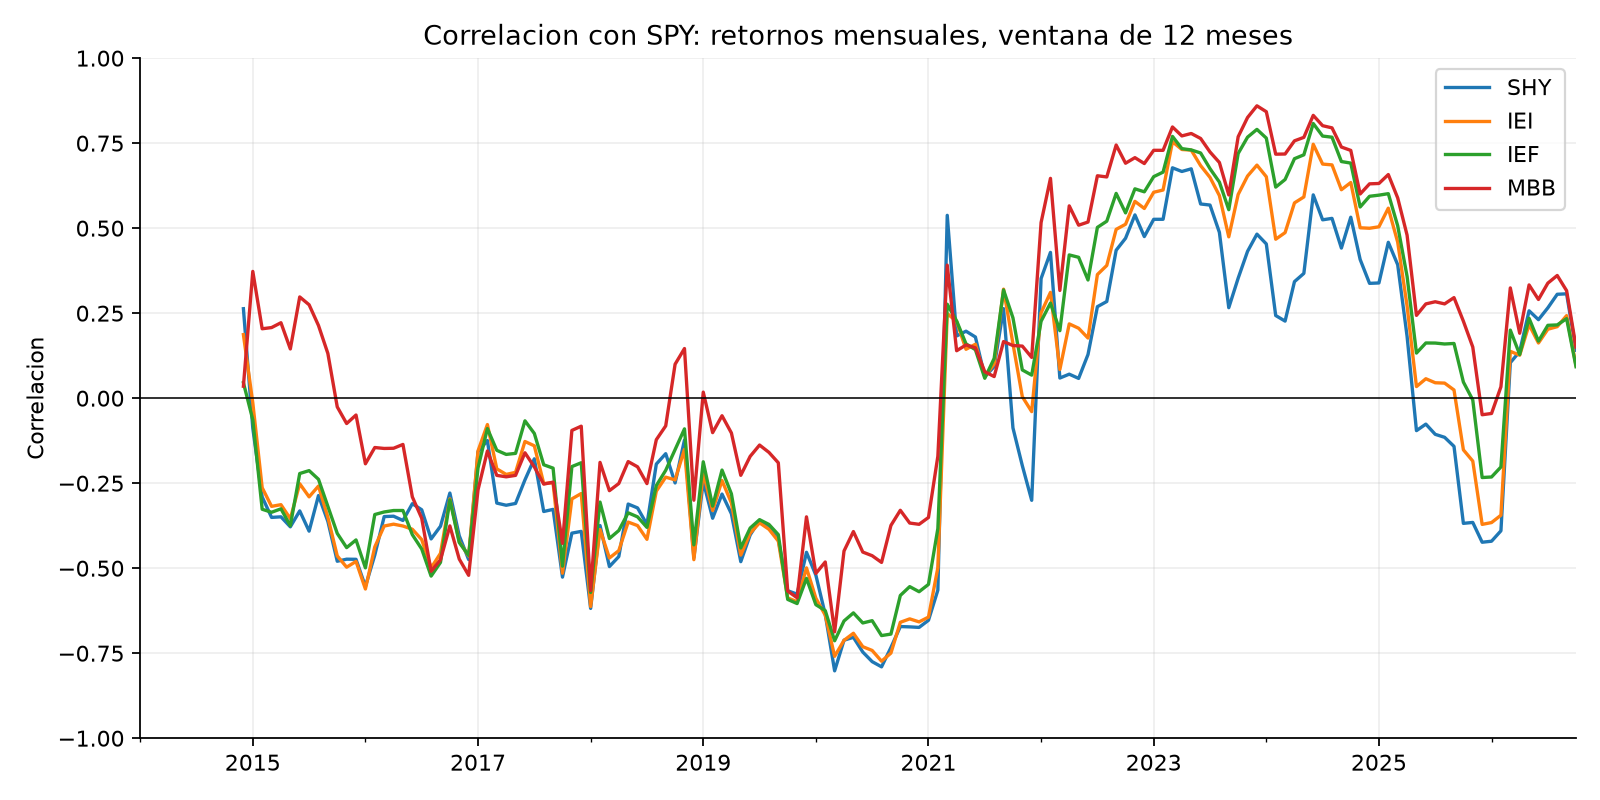

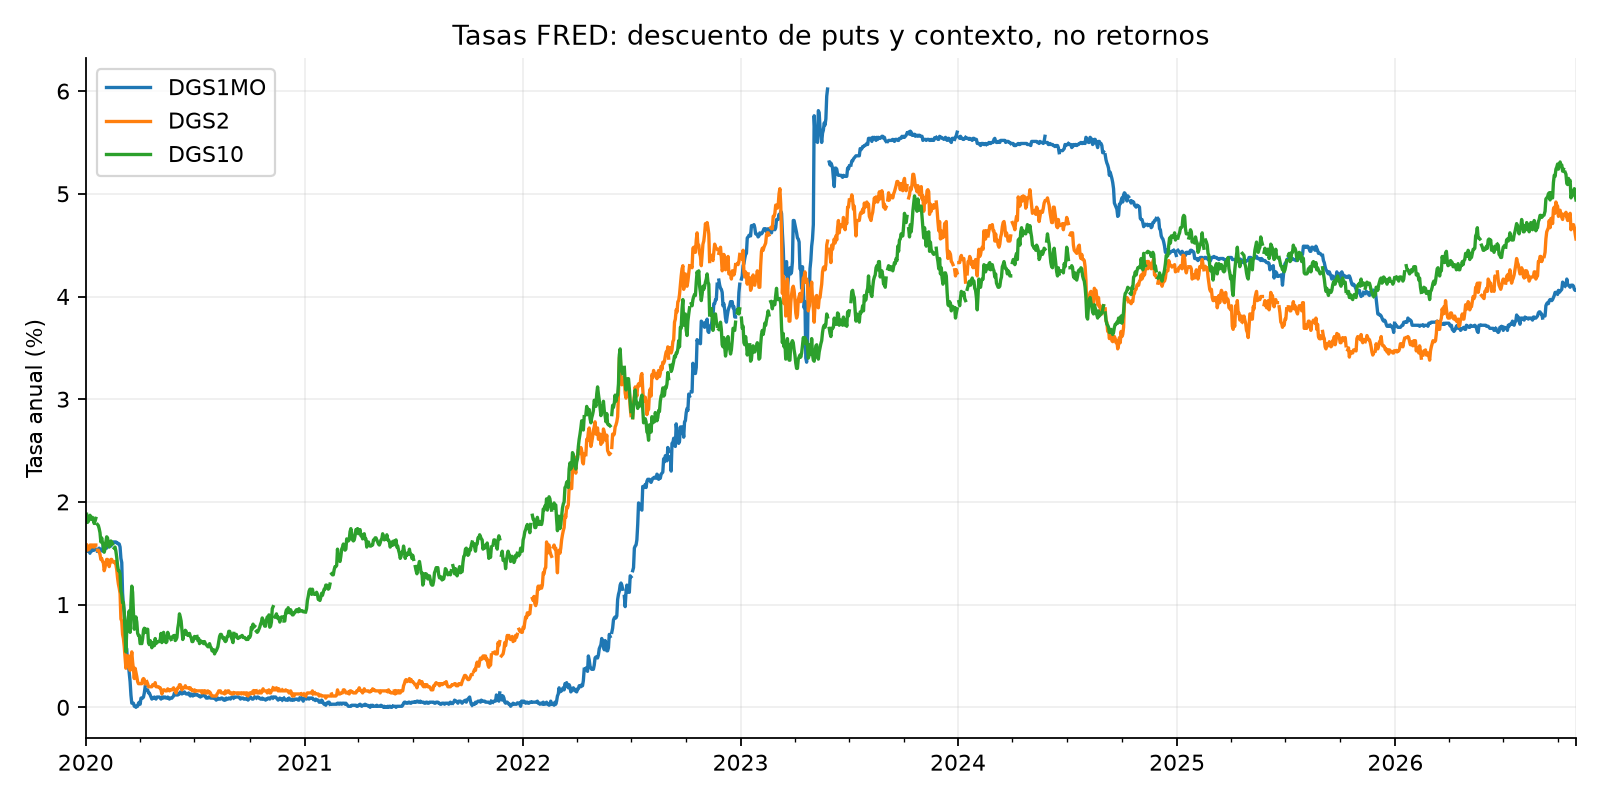

# FEES: una cartera por hipótesis

Se comparan **una referencia y cuatro carteras distintas**, una por idea del usuario. Datos hasta 2026-10-31, 82 meses desde enero de 2020. Ejecutar `python analisis.py` para regenerar todas las cifras.

La referencia aproxima el bloque USD de **69%** de la asignación estratégica. Faltan Europa 19%, Japón 9% y China 3%. Las métricas son por 100 invertidos en ese bloque y no representan el retorno del FEES completo. La política actual aplicada al pasado es un contrafactual, incluso antes de noviembre de 2023.

**H2 incluye primas y pagos teóricos de puts, no precios históricos observados de opciones.** Se incorpora para estudiar la idea, con su costo y sus límites. Simularla no significa que esté autorizada por la política vigente.

## Diseño de las cuatro carteras

- **H1, más letras:** mover 10 pp del fondo desde Treasury 7–10 años (IEF) hacia letras (BIL). Es la traducción propuesta por el asistente de reducir exposición a bonos largos cuando su correlación con acciones preocupa. No incorpora acciones ni activa señales según correlaciones futuras. Cambia la asignación estratégica.
- **H2, puts de cobre:** conservar la cartera de referencia y comprar puts hipotéticas cada mes. Nocional equivalente a 10% del fondo, strike 95% del precio inicial y plazo 1/12 de año. La prima y fricción se financian reduciendo BIL ese mes. No se posee un futuro descubierto.
- **H3, menor duración:** mover 2 pp desde IEF hacia SHY (Treasury 1–3 años). Conservar el 40% total de Treasuries, el 10% de letras y el 15% MBS.
- **H4, menos MBS:** reducir MBB del 15% al 10% y subir BIL del 10% al 15%. La sensibilidad también prueba 20% MBS. Estos cambios requieren modificar la asignación.

Pesos sobre el fondo completo, **no normalizados**. Suman 69%; el 31% no modelado se supone idéntico entre escenarios. La última columna es nocional subyacente de la opción y no se suma a los pesos de activos. La prima efectiva de H2 varía cada mes y se descuenta de BIL.

|                        |   BIL |    SHY |    IEI |    IEF |   STIP |   MBB |   nocional_put_pct |
|:-----------------------|------:|-------:|-------:|-------:|-------:|------:|-------------------:|
| Referencia proxy USD   |    10 | 13.333 | 13.333 | 13.333 |      4 |    15 |                  0 |
| H1 Mas letras          |    20 | 13.333 | 13.333 |  3.333 |      4 |    15 |                  0 |
| H2 Puts cobre (modelo) |    10 | 13.333 | 13.333 | 13.333 |      4 |    15 |                 10 |
| H3 Treasury corto      |    10 | 15.333 | 13.333 | 11.333 |      4 |    15 |                  0 |
| H4 Menos MBS           |    15 | 13.333 | 13.333 | 13.333 |      4 |    10 |                  0 |

## Filtro normativo

| cartera                | hipotesis                            | estado_normativo                                                | evidencia                                  |
|:-----------------------|:-------------------------------------|:----------------------------------------------------------------|:-------------------------------------------|
| Referencia proxy USD   | Referencia                           | Referencia proxy; cumplimiento no certificado                   | Retornos ETF proxy                         |
| H1 Mas letras          | 1. Menor dependencia de bonos largos | Requiere cambiar asignacion y evaluar riesgo ex ante            | Retornos ETF proxy                         |
| H2 Puts cobre (modelo) | 2. Cobertura con puts de cobre       | Instrumento fuera de la politica consultada; simulacion teorica | Primas teoricas, subyacente continuo proxy |
| H3 Treasury corto      | 3. Menor duracion Treasury           | Pesos de clases conservados; TE ex ante no verificado           | Retornos ETF proxy                         |
| H4 Menos MBS           | 4. Menor ponderacion MBS             | Requiere cambiar el 15% estrategico de MBS                      | Retornos ETF proxy                         |

Las restricciones se mantienen como criterio de decisión: las carteras fuera de política se muestran como hipótesis y no se recomiendan para ejecución bajo las reglas actuales. Los ETFs son proxies, no órdenes elegibles certificadas. El TE realizado aproximado no reemplaza el cálculo ex ante del custodio. H2 y H4 no reciben un TE soberano, porque ese número no decidiría su admisibilidad.

## Comparación del bloque USD

Retorno compuesto y volatilidad anual en %, caída y peor mes en %. La caída incluye el capital inicial y solo observa cierres mensuales. Diferencia CAGR en puntos porcentuales; TE proxy en puntos base anuales del mandato soberano 85%, suponiendo idéntico el resto.

|                        |   retorno_anual_pct |   volatilidad_anual_pct |   caida_max_mensual_pct |   peor_mes_pct |   diferencia_cagr_pp |   te_proxy_soberano_pb |
|:-----------------------|--------------------:|------------------------:|------------------------:|---------------:|---------------------:|-----------------------:|
| Referencia proxy USD   |               1.268 |                   4.018 |                 -11.088 |         -2.965 |                0     |                  0     |
| H1 Mas letras          |               1.695 |                   3.01  |                  -7.904 |         -2.249 |                0.426 |                 85.21  |
| H2 Puts cobre (modelo) |              -1.009 |                   4.146 |                 -16.47  |         -3.342 |               -2.277 |                nan     |
| H3 Treasury corto      |               1.326 |                   3.861 |                 -10.617 |         -2.863 |                0.058 |                 13.566 |
| H4 Menos MBS           |               1.426 |                   3.587 |                  -9.94  |         -2.581 |                0.157 |                nan     |

![Referencia y cuatro carteras](figuras/riqueza.png)

![Caídas mensuales](figuras/caidas.png)

## Qué produce la simulación de puts

Con los supuestos centrales, H2 devuelve -1.01% anual del bloque, con caída máxima mensual de -16.47%. La prima media anualizada es 2.02% del capital total hipotético tras el costo de rebalanceo de cada mes y los pagos medios anualizados son 0.66%. Son promedios mensuales por 12, no sumas de caja sobre un capital inicial constante.

Hubo 14 meses de caída del proxy del cobre superior a 5%. En ellos, la diferencia media H2 menos referencia fue 0.22 pp mensuales del bloque. Esto describe la protección frente a ese subyacente y el costo del seguro. **No demuestra cobertura de ingresos fiscales ni de todas las pérdidas de bonos.** No se modelan ingresos tributarios, producción ni retiros del FEES.

![Primas y pagos de puts teóricas](figuras/puts.png)

El CSV `puts_auditoria.csv` guarda para cada mes precio inicial y final, strike, volatilidad histórica conocida al entrar, volatilidad del modelo, tasa, prima, fricción, pago y retorno. Permite seguir el cálculo de un mes sin una caja negra.

La valoración usa **Black-76 europeo**, con volatilidad de los 63 retornos diarios anteriores multiplicada por 1.25. Ese multiplicador es un supuesto, no volatilidad implícita observada. Se añade fricción del 10% de la prima. Se descuenta el rendimiento BIL sacrificado al pagar prima y fricción. El programa rechaza una prima superior a las letras disponibles.

`HG=F` es un proxy continuo: el precio inicial y final pueden corresponder a vencimientos distintos. Por ello se simula una **opción europea hipotética sobre ese proxy**, no contratos COMEX históricos identificados. No se replica el rollover de un contrato negociable, el ejercicio americano, la entrega del futuro, la malla de strikes, el spread real ni contratos enteros de 25.000 libras. Los resultados son condicionales y no constituyen un backtest ejecutable de opciones reales.

## Sensibilidad del seguro y de MBS

La siguiente tabla mantiene el nocional de 10% y varía strike y multiplicador de volatilidad. `sensibilidad_puts.csv` contiene las 27 combinaciones de strikes 90/95/100%, volatilidad histórica por 1/1,25/1,5 y nocionales 5/10/20%. Se muestran todas sin elegir la mejor.

|   retorno_anual_pct |   volatilidad_anual_pct |   caida_max_mensual_pct |   peor_mes_pct |   strike |   multiplicador_vol |   nocional |
|--------------------:|------------------------:|------------------------:|---------------:|---------:|--------------------:|-----------:|
|               0.824 |                   4.015 |                 -11.58  |         -3.049 |     0.9  |                1    |        0.1 |
|               0.196 |                   4.026 |                 -12.719 |         -3.13  |     0.9  |                1.25 |        0.1 |
|              -0.592 |                   4.043 |                 -14.719 |         -3.225 |     0.9  |                1.5  |        0.1 |
|               0.119 |                   4.126 |                 -13.339 |         -3.218 |     0.95 |                1    |        0.1 |
|              -1.009 |                   4.146 |                 -16.47  |         -3.342 |     0.95 |                1.25 |        0.1 |
|              -2.198 |                   4.171 |                 -20.041 |         -3.471 |     0.95 |                1.5  |        0.1 |
|              -1.002 |                   4.25  |                 -16.243 |         -3.229 |     1    |                1    |        0.1 |
|              -2.398 |                   4.273 |                 -21.727 |         -3.373 |     1    |                1.25 |        0.1 |
|              -3.775 |                   4.3   |                 -28.748 |         -3.517 |     1    |                1.5  |        0.1 |

Para MBS, cada cambio se financia con letras. El 15% es la referencia oficial; 10% y 20% son alternativas hipotéticas que cambian la asignación.

|   retorno_anual_pct |   volatilidad_anual_pct |   caida_max_mensual_pct |   peor_mes_pct |   peso_mbs_sobre_fondo |
|--------------------:|------------------------:|------------------------:|---------------:|-----------------------:|
|               1.426 |                   3.587 |                  -9.94  |         -2.581 |                   0.1  |
|               1.268 |                   4.018 |                 -11.088 |         -2.965 |                   0.15 |
|               1.109 |                   4.453 |                 -12.224 |         -3.349 |                   0.2  |

## Correlación, estrés e incertidumbre

La primera hipótesis se evalúa con su propia cartera y con el diagnóstico de correlación. SPY solo se usa para diagnóstico. Una correlación positiva no implica ausencia total de diversificación.

| periodo    |    IEF |    IEI |    MBB |    SHY |
|:-----------|-------:|-------:|-------:|-------:|
| 2014-2019  | -0.338 | -0.347 | -0.165 | -0.322 |
| 2020-2021  | -0.373 | -0.477 | -0.205 | -0.577 |
| 2022       |  0.607 |  0.558 |  0.69  |  0.475 |
| 2023-corte |  0.44  |  0.359 |  0.519 |  0.249 |

![Correlación móvil](figuras/correlacion.png)

Retornos acumulados en episodios fijados por calendario. H2 sigue dependiendo de primas teóricas.

|         |   Referencia proxy USD |   H1 Mas letras |   H2 Puts cobre (modelo) |   H3 Treasury corto |   H4 Menos MBS |
|:--------|-----------------------:|----------------:|-------------------------:|--------------------:|---------------:|
| 2020 T1 |                  4.289 |           2.85  |                    5.778 |               4.067 |          4.125 |
| 2022    |                 -8.134 |          -5.729 |                   -9.853 |              -7.802 |         -7.201 |

Bootstrap pareado circular con 2000 repeticiones y semilla 20261108. Aquí se muestran bloques de seis meses; `incertidumbre.csv` también incluye 3 y 12. Intervalos individuales del 95% para diferencias de **medias mensuales por 12**, en pp anuales, no diferencias de CAGR. No corrigen comparaciones múltiples ni la selección retrospectiva. En H2 tampoco incorporan error de valoración de opciones.

| cartera                |   bloque_meses |   media_anualizada_pp |   ic95_inferior_pp |   ic95_superior_pp |
|:-----------------------|---------------:|----------------------:|-------------------:|-------------------:|
| H1 Mas letras          |              6 |                 0.386 |             -0.366 |              1.081 |
| H2 Puts cobre (modelo) |              6 |                -2.269 |             -3.132 |             -1.427 |
| H3 Treasury corto      |              6 |                 0.051 |             -0.065 |              0.157 |
| H4 Menos MBS           |              6 |                 0.139 |             -0.109 |              0.412 |

`sensibilidad_periodos.csv` compara 2015–2019, 2020–2021, 2022 y 2023–corte con las mismas cinco carteras. La ventana anterior a 2020 comienza en 2015 para asegurar calentamiento de volatilidad del cobre. `sensibilidad_costos.csv` prueba 0/5/10 pb de costos de activos; la fricción propia de puts se mantiene separada.

## Moneda y límites

Conversión ilustrativa a CLP: `(1 + retorno USD) × (1 + cambio CLP por USD) − 1`, con Yahoo CLP=X. No es dólar observado y sus horarios pueden diferir del cierre de ETF.

|                        |   retorno_anual_pct |   volatilidad_anual_pct |   caida_max_mensual_pct |   peor_mes_pct |
|:-----------------------|--------------------:|------------------------:|------------------------:|---------------:|
| Referencia proxy USD   |               5.806 |                  12.934 |                 -17.981 |         -7.76  |
| H1 Mas letras          |               6.251 |                  12.96  |                 -17.355 |         -7.474 |
| H2 Puts cobre (modelo) |               3.426 |                  13.498 |                 -20.132 |         -7.979 |
| H3 Treasury corto      |               5.866 |                  12.93  |                 -17.848 |         -7.721 |
| H4 Menos MBS           |               5.97  |                  13.009 |                 -18.028 |         -7.665 |

Rebalanceo mensual, sin aportes ni retiros, con costo de 5 pb por dólar comprado o vendido, incluida la compra inicial. Los cierres ajustados aproximan reinversión de distribuciones y ya incluyen gastos internos de ETF. FRED DGS1MO se usa solo como proxy de descuento para la prima; DGS2/DGS10 dan contexto. Ninguna variación de tasas se interpreta como retorno de bonos.

La referencia divide el 40% Treasury en tercios SHY/IEI/IEF, supuesto que no replica ponderaciones por capitalización. STIP es TIPS 0–5 años, distinto del comparador 1–10. Los demás ETF también tienen desajustes de índice, gastos y gestión. Sin índices oficiales ni cartera global no se certifica rendimiento efectivo ni cumplimiento del FEES. Las hipótesis se diseñaron con conocimiento del pasado; no hay validación independiente fuera de muestra.

## Fuentes

[Política FEES](https://www.hacienda.cl/areas-de-trabajo/finanzas-internacionales/fondos-soberanos/fondo-de-estabilizacion-economica-y-social/politica-de-inversion), [directrices vigentes](https://www.hacienda.cl/areas-de-trabajo/finanzas-internacionales/fondos-soberanos/fondo-de-estabilizacion-economica-y-social/politica-de-inversion/pauta-de-inversion-vigente), [Yahoo cobre](https://finance.yahoo.com/quote/HG=F/), [FRED DGS1MO](https://fred.stlouisfed.org/series/DGS1MO), [Black (1976)](https://doi.org/10.1016/0304-405X(76)90024-6), [CME: opciones de cobre](https://www.cmegroup.com/markets/metals/base/copper.contractSpecs.options.html), [CME: datos históricos DataMine](https://www.cmegroup.com/datamine.html). Las URLs exactas y hashes de las descargas están en `data/metadatos.json`.

El alcance académico completo también requiere FRP. Siguen pendientes la revisión y defensa del equipo, el memo final y las firmas del anexo IA.


In [20]:
from IPython.display import Image, Markdown, display
for nombre in ["riqueza", "caidas", "puts", "correlacion", "tasas"]:
    display(Image(filename=str(RAIZ / f"results/figuras/{nombre}.png")))
display(Markdown((RAIZ / "results/informe.md").read_text()))

## Verificación

Las pruebas comprueban cinco carteras, financiación de primas, pagos, ausencia de datos futuros, capital inicial, costos, hashes y conversión CLP. No certifican el tracking error oficial ex ante ni primas de mercado.

In [21]:
import subprocess
import sys
subprocess.run([sys.executable, 'verificar.py'], check=True)

test_analisis_no_necesita_red (__main__.ArchivosReales.test_analisis_no_necesita_red) ... ok
test_cinco_carteras_reales_sin_red (__main__.ArchivosReales.test_cinco_carteras_reales_sin_red) ... 

ok
test_integridad_datos (__main__.ArchivosReales.test_integridad_datos) ... ok
test_moneda_clp (__main__.ArchivosReales.test_moneda_clp) ... ok
test_resultados_vs_activos (__main__.ArchivosReales.test_resultados_vs_activos) ... ok
test_cagr_compuesto (__main__.Calculos.test_cagr_compuesto) ... ok
test_cobertura_cero_reproduce_referencia (__main__.Calculos.test_cobertura_cero_reproduce_referencia) ... 

ok
test_perdida_inicial_incluida (__main__.Calculos.test_perdida_inicial_incluida) ... ok
test_pesos_y_acciones (__main__.Calculos.test_pesos_y_acciones) ... ok
test_prima_black76_caso_cerrado_y_limites (__main__.Calculos.test_prima_black76_caso_cerrado_y_limites) ... ok
test_prima_sin_datos_futuros (__main__.Calculos.test_prima_sin_datos_futuros) ... ok
test_put_financiada_y_pago (__main__.Calculos.test_put_financiada_y_pago) ... ok
test_rebalanceo_incluye_pago_del_seguro (__main__.Calculos.test_rebalanceo_incluye_pago_del_seguro) ... 

ok
test_rebalanceo_y_costos (__main__.Calculos.test_rebalanceo_y_costos) ... ok
test_rechaza_cambio_mbs_en_escenario_duracion (__main__.Calculos.test_rechaza_cambio_mbs_en_escenario_duracion) ... ok
test_rechaza_prima_superior_al_efectivo (__main__.Calculos.test_rechaza_prima_superior_al_efectivo) ... ok
test_rechaza_traspaso_excesivo (__main__.Calculos.test_rechaza_traspaso_excesivo) ... ok
test_una_cartera_por_hipotesis_y_estado_normativo (__main__.Calculos.test_una_cartera_por_hipotesis_y_estado_normativo) ... ok

----------------------------------------------------------------------
Ran 18 tests in 1.010s

OK


CompletedProcess(args=['/root/assetpricing/presentacionasset/.venv/bin/python', 'verificar.py'], returncode=0)

## Qué falta para el trabajo académico completo

Revisar los supuestos y resultados con el equipo, analizar FRP y preparar el memo de hasta 10 páginas. Consultar `docs/guia-codigo.md` para practicar la defensa. Revisar `docs/registro-ia.md` y completar los aportes propios y las firmas antes de entregar. Ninguna firma está supuesta.
